# Changing Task Count

**Question:** How does a learner with capacity for two teachers cope as the number of recurring tasks falls from four to one and rises back to four?

Four fixed teachers each map 21 independent ±1 inputs through 10 LTUs to 10 linear outputs. Teacher weights are ±1 and every target has independent Gaussian noise of standard deviation 1. Training runs in seven phases of 500k examples with 4, 3, 2, 1, 2, 3 and 4 active teachers. Going down drops teacher 4, then 3, then 2; going up brings back 2, 3 and 4, so every returning teacher has been seen before. Every 10,000 examples, switch to the next active teacher. All tasks share input and output coordinates; no task ID is supplied.

The learner has **21 inputs → 20 LTUs → 10 linear outputs**, enough features for two teachers. Weights, optimizer state, and centering statistics persist across switches and phases. All biases are weights on constant-1 inputs. Predictions are scored before learning each target.

Compare five SGD step sizes and network Autostep, using the same five seeds for every configuration. SGD uses fan-in initialization and sigmoid surrogate derivatives. Autostep uses **meta step 0.02, initial ln(α) = −8**, hidden weights uniform in ±α₀, and uncompensated activation/derivative centering (rate 1e-3). Readouts start at zero. Autostep uses the `squared_inputs` implementation from the network Autostep notebooks, with normalization time constant 1e4.

**Privileged reference:** a shared linear Autostep readout of all 40 fixed, true teacher features, centered at 0.5, including those of inactive teachers. It receives neither the active task ID nor correct output weights. Only its readout learns, with the same Autostep settings and five seeds. This measures achievable readout adaptation with perfect features; it is not a proven optimal bound. Noise RMSE 1 is a lower bound, not the expected online optimum after unannounced switches.

Methods share teachers, switches, inputs and noise for matching seed IDs. Both plots compare the SGD rate with the lowest mean per-seed RMSE over the whole run against Autostep and the ideal-feature baseline, using the same runs without retraining: one for the way down (4 → 1 tasks), one for the way back up (2 → 4 tasks), each showing the first and last 80k examples of every phase.

**Diagnostic:** group each learner's hidden units by the teacher LTU they best match at the start of the 1-task phase, then track each group from the 2-task phase before it to the 2-task phase after it: how well units keep that match (absolute correlation over 1000 random inputs), the norm of their output weights, and, for Autostep, their input ln(α). Weights are snapshots at the end of each 1k-step window, not window means.

In [1]:
from functools import partial
from pathlib import Path
from time import perf_counter
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# Problem
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10
N_TASKS = 4
N_HIDDEN = 2 * WIDTH  # capacity for two of the four teachers

# Autostep: uncompensated centering and small hidden initialization.
INIT_RATE, META_RATE, EMA_RATE = np.exp(-8.), 0.02, 1e-3

# Training
ACTIVE = (4, 3, 2, 1, 2, 3, 4)  # active teachers in each phase
PHASE_STEPS = 500_000
STEPS = len(ACTIVE) * PHASE_STEPS
PLOT_STEPS = 80_000  # steps shown at the start and at the end of each phase
PERIOD = 10_000
BLOCKS = STEPS // PERIOD
WINDOW = 1000
SGD_EXPONENTS = (-9, -8, -7, -6, -5)
SGD_RATES = [2.**p for p in SGD_EXPONENTS]
N_SEEDS = 5
assert PHASE_STEPS % PERIOD == 0 and PERIOD % WINDOW == 0

## Task

In [3]:
def init_teacher(key):
    input_key, _, output_key = jax.random.split(key, 3)
    w = jax.random.rademacher(input_key, (WIDTH, N_INPUTS), dtype=jnp.float32)
    v = jax.random.rademacher(output_key, (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    return w, v


def target(teacher, x):
    w, v = teacher
    return v @ (w @ x > 0).astype(jnp.float32)

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True,
                       tau=1e4, version='squared_inputs')

class Learner(NamedTuple):
    weights: tuple
    opt: object
    means: tuple
    slopes: tuple


def init_learner(key, widths, method):
    weights = []
    fan_in = N_INPUTS
    for width, subkey in zip(widths, jax.random.split(key, len(widths))):
        bound = INIT_RATE if method == 'Autostep' else np.sqrt(3 / fan_in)
        w = jax.random.uniform(subkey, (width, fan_in + 1), minval=-bound, maxval=bound)
        weights.append(w.at[:, -1].set(0.))
        fan_in = width
    weights.append(jnp.zeros((N_OUTPUTS, fan_in + 1)))
    weights = tuple(weights)
    return Learner(weights, OPTIMIZER.init(weights) if method == 'Autostep' else None,
                   tuple(jnp.full(w.shape[0], .5) for w in weights[:-1]),
                   tuple(jnp.zeros_like(w).at[:, -1].set(.25) for w in weights[:-1]))


def forward(weights, x, learner, method):
    sources, means, slopes = [], [], []
    for w, mean, slope in zip(weights[:-1], learner.means, learner.slopes):
        source = jnp.append(x, 1.)
        sources.append(source[None])
        z = w @ source
        x = ltu(z)
        if method == 'Autostep':
            # Same uncompensated centering and centered surrogate as network_autostep.
            mean = mean + EMA_RATE * (jax.lax.stop_gradient(x) - mean)
            sigmoid = jax.nn.sigmoid(z)
            derivative = jax.lax.stop_gradient(sigmoid * (1 - sigmoid))
            slope = slope + EMA_RATE * (derivative[:, None] * jax.lax.stop_gradient(source) - slope)
            correction = jnp.sum(slope * w, axis=1)
            x = x - mean + (jax.lax.stop_gradient(correction) - correction)
        means.append(mean)
        slopes.append(slope)
    sources.append(jnp.append(x, 1.)[None])
    return weights[-1] @ sources[-1][0], (tuple(sources), tuple(means), tuple(slopes))


def update(learner, x, y, method, rate):
    def loss(weights):
        prediction, aux = forward(weights, x, learner, method)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, means, slopes)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    if method == 'Autostep':
        updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.weights)
    else:
        updates, opt = jax.tree.map(lambda g: -rate * g, grads), None
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, means, slopes), 2 * loss_value / N_OUTPUTS

## Training

In [5]:
def train(seed, rate, method, reference=False):
    teacher_key, learner_key, schedule_key, rng = jax.random.split(jax.random.PRNGKey(seed), 4)
    teachers = jax.vmap(init_teacher)(jax.random.split(teacher_key, N_TASKS))
    if reference:
        weights = (jnp.zeros((N_OUTPUTS, N_TASKS * WIDTH + 1)),)
        learner = Learner(weights, OPTIMIZER.init(weights), (), ())
    else:
        learner = init_learner(learner_key, (N_HIDDEN,), method)

    active = jnp.repeat(jnp.array(ACTIVE), PHASE_STEPS // PERIOD)

    def block(carry, block_id):
        learner, rng, task_id = carry
        # Cycle through the active teachers 0, ..., active - 1.
        task_id = jnp.where(block_id == 0, task_id, (task_id + 1) % active[block_id])
        teacher = jax.tree.map(lambda w: w[task_id], teachers)

        def sample(carry, _):
            learner, rng = carry
            rng, x_key, noise_key = jax.random.split(rng, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(teacher, x) + jax.random.normal(noise_key, (N_OUTPUTS,))
            if reference:
                # All true features, with no indication of which task is active.
                x = (jnp.einsum('thi,i->th', teachers[0], x) > 0).astype(jnp.float32).reshape(-1) - .5
            learner, mse = update(learner, x, y, method, rate)
            return (learner, rng), (mse, learner.opt.beta if method == 'Autostep' else ())

        def record(carry, _):
            # Window means of the MSE and of every weight's ln(step size); every weight at the window's end.
            carry, records = jax.lax.scan(sample, carry, length=WINDOW)
            return carry, (*jax.tree.map(lambda r: r.mean(axis=0), records), carry[0].weights)
        (learner, rng), records = jax.lax.scan(record, (learner, rng), length=PERIOD // WINDOW)
        return (learner, rng, task_id), records

    task_id = jax.random.randint(schedule_key, (), 0, N_TASKS)
    _, records = jax.lax.scan(block, (learner, rng, task_id), jnp.arange(BLOCKS))
    return records


@partial(jax.jit, static_argnames=('method', 'reference'))
def train_many(seeds, rates, method, reference=False):
    one = partial(train, method=method, reference=reference)
    # Inner vmap: seeds; outer vmap: step sizes.
    return jax.vmap(jax.vmap(one, in_axes=(0, None)), in_axes=(None, 0))(seeds, rates)


def run(method, rates=None, reference=False):
    started = perf_counter()
    rates = jnp.asarray([INIT_RATE] if rates is None else rates, dtype=jnp.float32)
    mse, beta, weights = jax.tree.map(np.asarray, train_many(jnp.arange(N_SEEDS), rates, method, reference))
    assert np.isfinite(mse).all()
    print(f'{method}{" ideal features" if reference else ""}: {perf_counter() - started:.1f}s including compilation')
    return mse, beta, weights

In [6]:
started = perf_counter()
sgd, _, sgd_weights = run('SGD', rates=SGD_RATES)
autostep, autostep_beta, autostep_weights = run('Autostep')
reference, _, _ = run('Autostep', reference=True)
seconds = perf_counter() - started
np.savez_compressed(RESULTS / 'changing_task_count.npz', sgd=sgd, autostep=autostep,
                    reference=reference, rates=SGD_RATES, period=PERIOD,
                    window=WINDOW, seconds=seconds)
print(f'Complete comparison: {seconds:.1f}s including compilation.')

SGD: 38.8s including compilation


Autostep: 84.1s including compilation


Autostep ideal features: 60.5s including compilation
Complete comparison: 183.4s including compilation.


## Plots

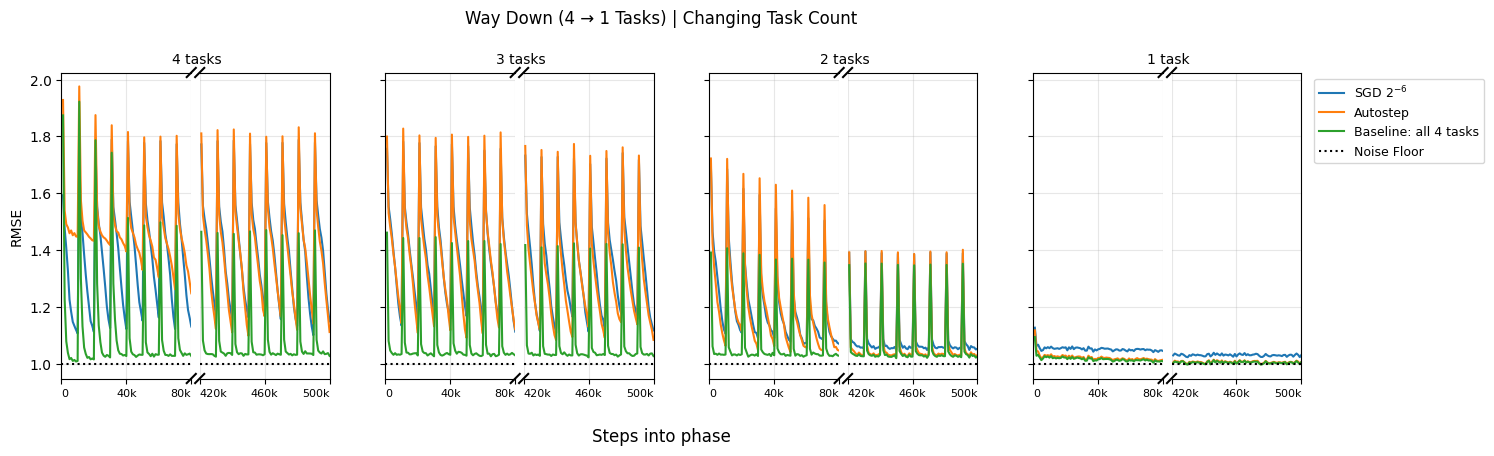

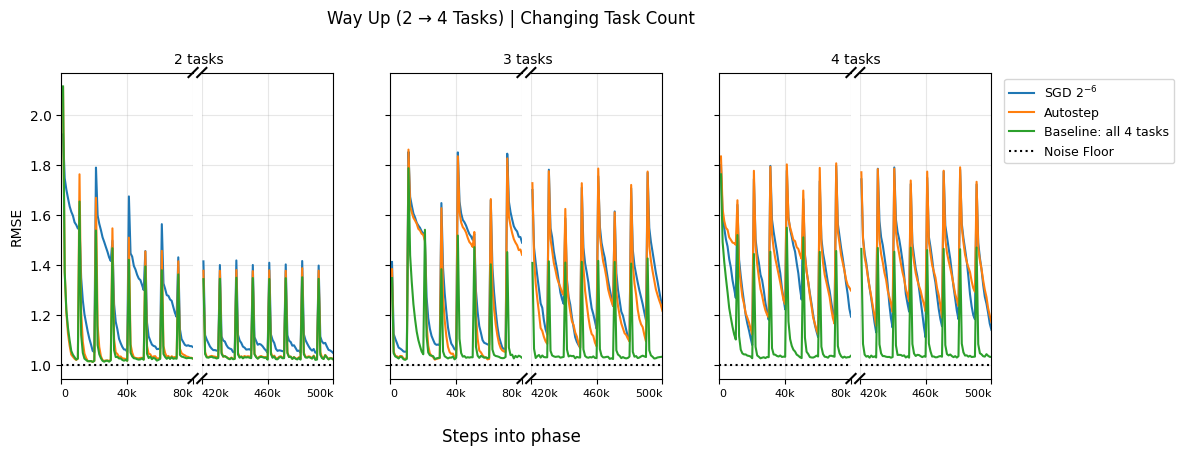

SGD $2^{-6}$, final-100k RMSE of each phase: 1.408 1.350 1.099 1.030 1.112 1.352 1.392
SGD $2^{-6}$, full-phase RMSE of each phase: 1.404 1.367 1.132 1.039 1.163 1.339 1.394
Autostep, final-100k RMSE of each phase: 1.393 1.319 1.077 1.006 1.071 1.309 1.398
Autostep, full-phase RMSE of each phase: 1.412 1.341 1.111 1.010 1.081 1.298 1.400
Baseline: all 4 tasks, final-100k RMSE of each phase: 1.090 1.079 1.066 1.004 1.064 1.078 1.090
Baseline: all 4 tasks, full-phase RMSE of each phase: 1.096 1.081 1.068 1.007 1.071 1.083 1.096
Comparison uses SGD 2^(-6), chosen by whole-run RMSE from the sweep.


In [7]:
x = np.arange(1, STEPS // WINDOW + 1) * WINDOW
sgd_labels = [rf'SGD $2^{{{p}}}$' for p in SGD_EXPONENTS]
best = int(np.argmin(np.sqrt(sgd.mean(axis=(2, 3))).mean(axis=1)))


def plot_phases(curves, phases, title):
    # Each phase gets a pair of panels, its first and last PLOT_STEPS; empty spacers separate phases.
    fig, axes = plt.subplots(1, 3 * len(phases) - 1, figsize=(4 * len(phases), 4.5), sharey=True,
                             gridspec_kw={'wspace': .08, 'width_ratios': ([1, 1, .3] * len(phases))[:-1]})
    for spacer in axes[2::3]:
        spacer.axis('off')
    for i, phase in enumerate(phases):
        start = phase * PHASE_STEPS
        pair = axes[3 * i:3 * i + 2]
        for ax, left in zip(pair, (0, PHASE_STEPS - PLOT_STEPS)):
            visible = (x > start + left) & (x <= start + left + PLOT_STEPS)
            for label, values in curves:
                values = values.reshape(len(values), -1)
                ax.plot(x[visible], np.sqrt(values[:, visible]).mean(axis=0), label=label)
            ax.axhline(1., color='black', ls=':', label='Noise Floor')
            ax.set_xlim(start + left, start + left + PLOT_STEPS)
            ticks = np.linspace(left, left + PLOT_STEPS, 3)
            ax.set_xticks(start + ticks, ['0' if t == 0 else f'{t / 1000:g}k' for t in ticks], fontsize=8)
            # Keep edge labels inside their panel so they don't collide across the narrow gaps.
            ax.get_xticklabels()[0].set_ha('left')
            ax.get_xticklabels()[-1].set_ha('right')
            ax.grid(True, alpha=.3)
        pair[0].spines['right'].set_visible(False)
        pair[1].spines['left'].set_visible(False)
        pair[1].tick_params(axis='y', left=False)
        # Diagonal bars mark the omitted middle of the phase.
        for ax, side in ((pair[0], 1), (pair[1], 0)):
            for height in (0, 1):
                ax.plot((side-.035, side+.035), (height-.015, height+.015),
                        transform=ax.transAxes, color='black', clip_on=False, lw=1.5)
        pair[0].text(1.04, 1.02, f'{ACTIVE[phase]} task' + 's' * (ACTIVE[phase] > 1),
                     transform=pair[0].transAxes, ha='center', va='bottom')
    axes[0].set_ylabel('RMSE')
    axes[-1].legend(fontsize=9, loc='upper left', bbox_to_anchor=(1.05, 1))
    fig.suptitle(title)
    fig.supxlabel('Steps into phase')
    fig.subplots_adjust(bottom=.16, top=.84)
    plt.show()


curves = [(sgd_labels[best], sgd[best]), ('Autostep', autostep[0]), ('Baseline: all 4 tasks', reference[0])]
plot_phases(curves, range(0, 4), 'Way Down (4 → 1 Tasks) | Changing Task Count')
plot_phases(curves, range(4, 7), 'Way Up (2 → 4 Tasks) | Changing Task Count')
for label, values in curves:
    values = values.reshape(N_SEEDS, len(ACTIVE), -1)
    for span, phase_values in (('final-100k', values[:, :, -100:]), ('full-phase', values)):
        rmse = np.sqrt(phase_values.mean(axis=2)).mean(axis=0)
        print(f'{label}, {span} RMSE of each phase:', ' '.join(f'{v:.3f}' for v in rmse))
print(f'Comparison uses SGD 2^({SGD_EXPONENTS[best]}), chosen by whole-run RMSE from the sweep.')

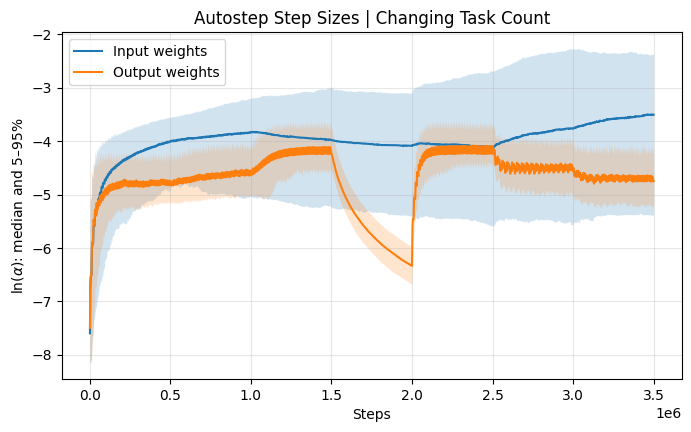

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, beta in zip(('Input weights', 'Output weights'), autostep_beta):
    # Pool every weight of every seed: (window, seed x weight).
    beta = np.moveaxis(beta[0].reshape(N_SEEDS, len(x), -1), 1, 0).reshape(len(x), -1)
    line, = ax.plot(x, np.median(beta, axis=1), label=label)
    ax.fill_between(x, *np.percentile(beta, [5, 95], axis=1), color=line.get_color(), alpha=.2, lw=0)
ax.set_xlabel('Steps')
ax.set_ylabel(r'$\ln(\alpha)$: median and 5–95%')
ax.set_title('Autostep Step Sizes | Changing Task Count')
ax.grid(True, alpha=.3)
ax.legend()
plt.show()

SGD $2^{-6}$: teacher 1 50, teacher 2 50, teachers 3–4 0 units over all seeds


Autostep: teacher 1 49, teacher 2 50, teachers 3–4 1 units over all seeds


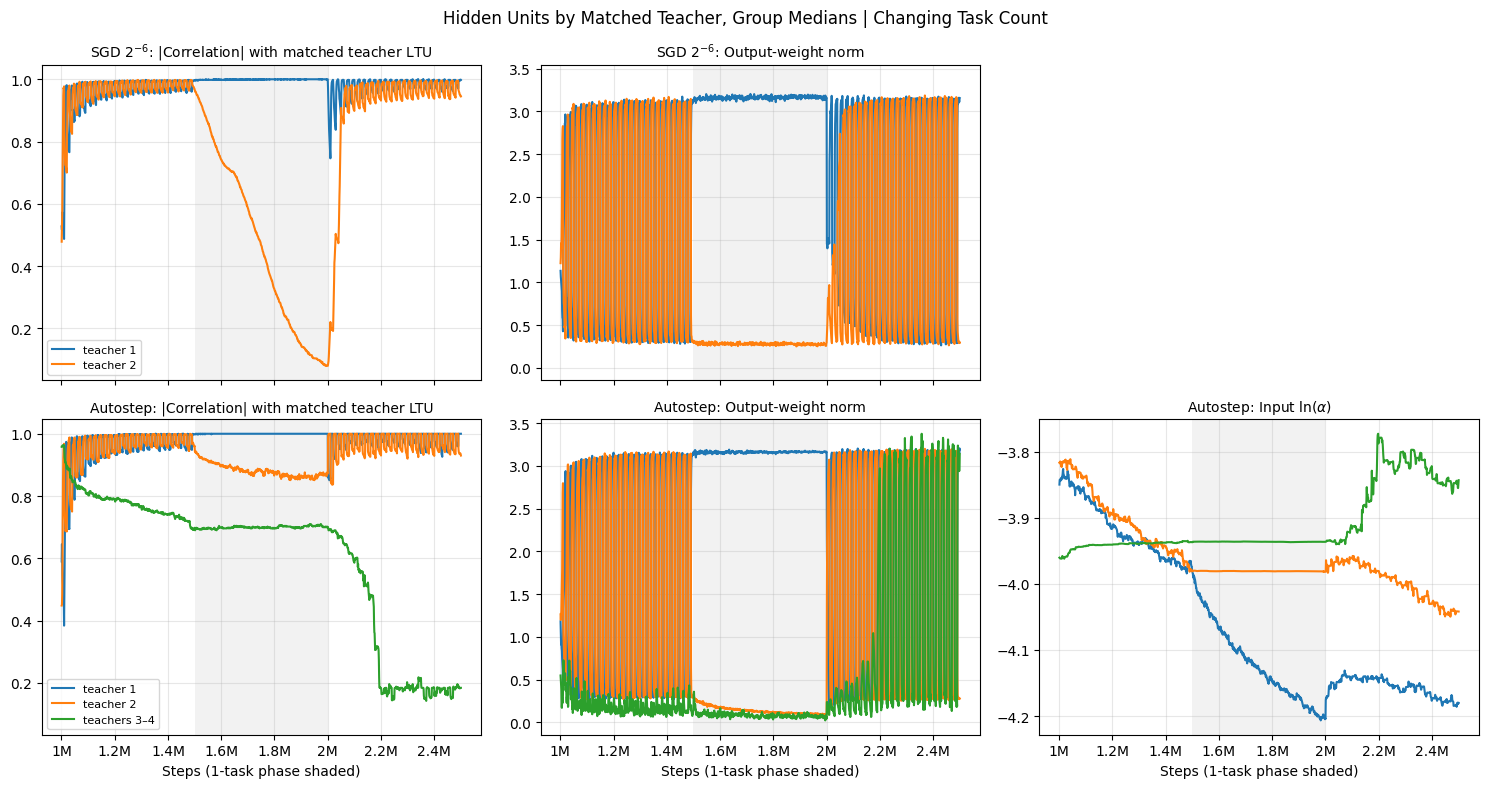

In [9]:
# Group hidden units by the teacher LTU they best match at the start of the 1-task phase.
phase = ACTIVE.index(1)
span = PHASE_STEPS // WINDOW
shown = slice((phase - 1) * span, (phase + 2) * span)  # the 1-task phase and the 2-task phases around it
probe = np.random.default_rng(0).choice([-1., 1.], (1000, N_INPUTS))
group_names = ['teacher 1', 'teacher 2', 'teachers 3–4']


def standardize(a):
    return (a - a.mean(-1, keepdims=True)) / (a.std(-1, keepdims=True) + 1e-8)


def unit_groups(hidden):
    # hidden: (seed, window, unit, input). Returns each unit's |correlation| with its matched teacher LTU over time,
    # and its group: the teacher of that LTU.
    matches, groups = [], []
    for seed, w in enumerate(hidden):
        teacher_key = jax.random.split(jax.random.PRNGKey(seed), 4)[0]
        teacher_w = np.asarray(jax.vmap(init_teacher)(jax.random.split(teacher_key, N_TASKS))[0]).reshape(-1, N_INPUTS)
        targets = standardize((teacher_w @ probe.T > 0).astype(np.float32))
        features = standardize((w @ np.append(probe, np.ones((len(probe), 1)), axis=1).T > 0).astype(np.float32))
        matched = np.abs(features[span - 1] @ targets.T).argmax(axis=1)
        matches.append(np.abs((features * targets[matched]).mean(-1)))
        groups.append(np.minimum(matched // WIDTH, 2))
    return np.array(matches), np.array(groups)


def windows(a):
    return a.reshape(N_SEEDS, len(x), *a.shape[-2:])[:, shown]


fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey='col')
for row, (method, (hidden, output)) in zip(axes, ((sgd_labels[best], [w[best] for w in sgd_weights]),
                                                  ('Autostep', [w[0] for w in autostep_weights]))):
    match, groups = unit_groups(windows(hidden))
    size = np.linalg.norm(windows(output)[..., :N_HIDDEN], axis=2)
    print(f'{method}:', ', '.join(f'{name} {(groups == g).sum()}' for g, name in enumerate(group_names)), 'units over all seeds')
    for g, name in enumerate(group_names):
        mask = groups == g
        if not mask.any():
            continue
        row[0].plot(x[shown], np.median(match.transpose(1, 0, 2)[:, mask], axis=1), color=f'C{g}', label=name)
        row[1].plot(x[shown], np.median(size.transpose(1, 0, 2)[:, mask], axis=1), color=f'C{g}')
        if method == 'Autostep':
            beta = windows(autostep_beta[0][0].reshape(N_SEEDS, len(x), N_HIDDEN, -1))
            row[2].plot(x[shown], np.median(beta.transpose(1, 0, 2, 3)[:, mask].reshape(len(beta[0]), -1), axis=1),
                        color=f'C{g}')
    for ax, title in zip(row, ('|Correlation| with matched teacher LTU', 'Output-weight norm', r'Input $\ln(\alpha)$')):
        ax.set_title(f'{method}: {title}', fontsize=10)
    row[0].legend(fontsize=8)
for ax in axes.flat:
    ax.axvspan(phase * PHASE_STEPS, (phase + 1) * PHASE_STEPS, color='gray', alpha=.1, lw=0)
    ax.xaxis.set_major_formatter(lambda t, _: f'{t / 1e6:g}M')
    ax.grid(True, alpha=.3)
axes[0, 2].remove()  # SGD has no adaptive step sizes
for ax in axes[1]:
    ax.set_xlabel('Steps (1-task phase shaded)')
fig.suptitle('Hidden Units by Matched Teacher, Group Medians | Changing Task Count')
fig.tight_layout()
plt.show()

All curves use five paired seeds; no uncertainty bands are shown.

**Result (183.4s on GPU):** SGD $2^{-6}$ has the lowest whole-run RMSE of the sweep. On the way up, each learner ends a phase at about the same RMSE as on the way down. Both tables give per-seed RMSE, averaged over seeds.

RMSE over the last 100k steps of each phase:

| Active tasks | 4 | 3 | 2 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|---|---|
| SGD $2^{-6}$ | 1.408 | 1.350 | 1.099 | 1.030 | 1.112 | 1.352 | 1.392 |
| Autostep | 1.393 | 1.319 | 1.077 | 1.006 | 1.071 | 1.309 | 1.398 |
| Ideal-feature baseline | 1.090 | 1.079 | 1.066 | 1.004 | 1.064 | 1.078 | 1.090 |

RMSE over each full 500k-step phase:

| Active tasks | 4 | 3 | 2 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|---|---|
| SGD $2^{-6}$ | 1.404 | 1.367 | 1.132 | 1.039 | 1.163 | 1.339 | 1.394 |
| Autostep | 1.412 | 1.341 | 1.111 | 1.010 | 1.081 | 1.298 | 1.400 |
| Ideal-feature baseline | 1.096 | 1.081 | 1.068 | 1.007 | 1.071 | 1.083 | 1.096 |

**Diagnostic:** At the start of the 1-task phase, SGD has 50 units matched to each of teachers 1 and 2 across the five seeds; Autostep has 49 and 50, plus one still matched to teacher 3 or 4. During the 1-task phase, the median match of SGD's teacher-2 units falls from about 1.0 to 0.08, while Autostep's falls only to about 0.86 and recovers as soon as teacher 2 returns. Autostep's teacher-2 units keep their input step sizes (ln(α) flat at about −3.98, close to SGD's fixed −4.16); only its teacher-1 units' input step sizes fall, from about −3.95 to −4.20. The teacher-2 units' output-weight norms stay at about 0.28 for SGD and fall from about 0.29 to 0.1 for Autostep.